# LoRA implementation with PyTorch

A from-scratch implementation of **LoRA: Low-Rank Adaptation of Large Language Models**
([Hu et al., 2021](https://arxiv.org/abs/2106.09685)) using PyTorch
[parametrizations](https://pytorch.org/tutorials/intermediate/parametrizations.html).

The idea: instead of fine-tuning a full weight matrix $W \in \mathbb{R}^{d_{out} \times d_{in}}$,
freeze it and learn a low-rank update

$$W' = W + \Delta W = W + \frac{\alpha}{r} B A, \qquad B \in \mathbb{R}^{d_{out} \times r},\ A \in \mathbb{R}^{r \times d_{in}},\ r \ll \min(d_{in}, d_{out})$$

We pre-train an (intentionally oversized) MLP on MNIST, then use LoRA to fine-tune it on the digit it
struggles with most, while training only a tiny fraction of the parameters and leaving the original
weights untouched.

Let's start by importing the necessary libraries.

In [1]:
import copy
import os

import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.utils.parametrize as parametrize
import torchvision
import torchvision.datasets as datasets
import torchvision.transforms as transforms
from tqdm import tqdm

print(f"torch {torch.__version__} | torchvision {torchvision.__version__}")

torch 2.15.0+cpu | torchvision 0.29.2+cpu


Make the run deterministic and pick the device.

In [2]:
# Make torch deterministic
_ = torch.manual_seed(0)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cpu


We will train a network to classify MNIST digits, then fine-tune it on a particular digit on which it
doesn't perform well.

In [3]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,)),  # MNIST mean / std
])

# Load the MNIST train and test sets
mnist_trainset = datasets.MNIST(root="./data", train=True, download=True, transform=transform)
mnist_testset = datasets.MNIST(root="./data", train=False, download=True, transform=transform)

train_loader = torch.utils.data.DataLoader(mnist_trainset, batch_size=10, shuffle=True)
# Evaluation needs neither shuffling nor small batches
test_loader = torch.utils.data.DataLoader(mnist_testset, batch_size=1000, shuffle=False)

Create the neural network to classify the digits, making it overly complicated to better show the power of LoRA.

In [4]:
# Create an overly expensive neural network to classify MNIST digits
# Daddy got money, so I don't care about efficiency
class RichBoyNet(nn.Module):
    def __init__(self, hidden_size_1=1000, hidden_size_2=2000):
        super().__init__()
        self.linear1 = nn.Linear(28 * 28, hidden_size_1)
        self.linear2 = nn.Linear(hidden_size_1, hidden_size_2)
        self.linear3 = nn.Linear(hidden_size_2, 10)
        self.relu = nn.ReLU()

    def forward(self, img):
        x = img.view(-1, 28 * 28)
        x = self.relu(self.linear1(x))
        x = self.relu(self.linear2(x))
        x = self.linear3(x)
        return x


net = RichBoyNet().to(device)

Train the network for only 1 epoch to simulate a complete general pre-training on the data.

In [5]:
def train(net, train_loader, epochs=5, total_iterations_limit=None, lr=1e-3, progress=True):
    loss_fn = nn.CrossEntropyLoss()
    # Only give the optimizer the parameters that are actually trainable
    # (once the network is frozen, that's just the LoRA matrices)
    optimizer = torch.optim.Adam([p for p in net.parameters() if p.requires_grad], lr=lr)

    total_iterations = 0
    for epoch in range(epochs):
        net.train()
        loss_sum = 0.0
        num_iterations = 0

        steps = len(train_loader)
        if total_iterations_limit is not None:
            steps = min(steps, total_iterations_limit - total_iterations)
        data_iterator = tqdm(train_loader, desc=f"Epoch {epoch + 1}", total=steps,
                             mininterval=1, disable=not progress)

        for x, y in data_iterator:
            num_iterations += 1
            total_iterations += 1
            x, y = x.to(device), y.to(device)

            optimizer.zero_grad()
            loss = loss_fn(net(x), y)
            loss.backward()
            optimizer.step()

            loss_sum += loss.item()
            # refresh=False lets tqdm's mininterval throttle redraws (keeps notebook outputs small)
            data_iterator.set_postfix(loss=loss_sum / num_iterations, refresh=False)

            if total_iterations_limit is not None and total_iterations >= total_iterations_limit:
                data_iterator.close()
                return


train(net, train_loader, epochs=1)

Epoch 1:   0%|          | 0/6000 [00:00<?, ?it/s]

Epoch 1:   1%|          | 72/6000 [00:01<01:23, 71.14it/s, loss=1.04]

Epoch 1:   2%|▏         | 146/6000 [00:02<01:20, 72.73it/s, loss=0.804]

Epoch 1:   4%|▎         | 219/6000 [00:03<01:19, 72.66it/s, loss=0.69] 

Epoch 1:   5%|▍         | 292/6000 [00:04<01:18, 72.66it/s, loss=0.61]

Epoch 1:   6%|▌         | 365/6000 [00:05<01:18, 72.02it/s, loss=0.576]

... (102 outputs left out)

Epoch 1:  98%|█████████▊| 5868/6000 [01:51<00:02, 50.87it/s, loss=0.237]

Epoch 1:  99%|█████████▊| 5920/6000 [01:52<00:01, 51.14it/s, loss=0.237]

Epoch 1: 100%|█████████▉| 5972/6000 [01:53<00:00, 51.18it/s, loss=0.235]

Epoch 1: 100%|██████████| 6000/6000 [01:53<00:00, 52.77it/s, loss=0.235]

Keep a copy of the original weights (cloning them) so later we can prove that fine-tuning with LoRA
doesn't alter them. We also keep a full copy of the pre-trained network for the rank experiment at the end.

In [6]:
original_weights = {name: param.clone().detach() for name, param in net.named_parameters()}
pretrained_net = copy.deepcopy(net)

Test the performance of the pre-trained network. We then pick the digit it gets wrong most often as
the target for fine-tuning.

In [7]:
@torch.no_grad()
def evaluate(net, loader=test_loader):
    # Returns (accuracy, number of misclassified test images per digit)
    net.eval()
    correct, total = 0, 0
    wrong_counts = torch.zeros(10, dtype=torch.long)
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        preds = net(x).argmax(dim=1)
        wrong = preds != y
        correct += (~wrong).sum().item()
        total += y.numel()
        wrong_counts += torch.bincount(y[wrong], minlength=10).cpu()
    return correct / total, wrong_counts.tolist()


def report(accuracy, wrong_counts):
    print(f"Accuracy: {accuracy:.3f}")
    for digit, count in enumerate(wrong_counts):
        print(f"Wrong counts for the digit {digit}: {count}")


base_accuracy, base_wrong_counts = evaluate(net)
report(base_accuracy, base_wrong_counts)

TARGET_DIGIT = max(range(10), key=lambda d: base_wrong_counts[d])
print(f"\nThe network struggles the most with the digit {TARGET_DIGIT}: we'll fine-tune on it.")

Accuracy: 0.958
Wrong counts for the digit 0: 13
Wrong counts for the digit 1: 30
Wrong counts for the digit 2: 39
Wrong counts for the digit 3: 62
Wrong counts for the digit 4: 30
Wrong counts for the digit 5: 29
Wrong counts for the digit 6: 49
Wrong counts for the digit 7: 60
Wrong counts for the digit 8: 10
Wrong counts for the digit 9: 99

The network struggles the most with the digit 9: we'll fine-tune on it.


Let's visualize how many parameters are in the original network, before introducing the LoRA matrices.

In [8]:
LORA_LAYERS = ["linear1", "linear2", "linear3"]

# Print the size of the weights matrices of the network
# Save the count of the total number of parameters
total_parameters_original = 0
for index, name in enumerate(LORA_LAYERS):
    layer = getattr(net, name)
    total_parameters_original += layer.weight.nelement() + layer.bias.nelement()
    print(f"Layer {index + 1}: W: {layer.weight.shape} + B: {layer.bias.shape}")
print(f"Total number of parameters: {total_parameters_original:,}")

Layer 1: W: torch.Size([1000, 784]) + B: torch.Size([1000])
Layer 2: W: torch.Size([2000, 1000]) + B: torch.Size([2000])
Layer 3: W: torch.Size([10, 2000]) + B: torch.Size([10])
Total number of parameters: 2,807,010


Define the LoRA parametrization as described in the paper.

`nn.Linear` stores its weight as `(out_features, in_features)`, so for $W' = W + \frac{\alpha}{r}BA$ to
type-check we need $B \in \mathbb{R}^{out \times r}$ and $A \in \mathbb{R}^{r \times in}$.

The full detail on how PyTorch parametrizations work is here:
https://pytorch.org/tutorials/intermediate/parametrizations.html

In [9]:
class LoRAParametrization(nn.Module):
    # Re-parametrizes a weight W of shape (features_out, features_in) as W + (B @ A) * alpha / rank

    def __init__(self, features_in, features_out, rank=1, alpha=1, device="cpu"):
        super().__init__()
        # Section 4.1 of the paper:
        #   We use a random Gaussian initialization for A and zero for B, so ∆W = BA is zero at the beginning of training
        self.lora_A = nn.Parameter(torch.zeros((rank, features_in), device=device))
        self.lora_B = nn.Parameter(torch.zeros((features_out, rank), device=device))
        nn.init.normal_(self.lora_A, mean=0, std=1)

        # Section 4.1 of the paper:
        #   We then scale ∆Wx by α/r , where α is a constant in r.
        #   When optimizing with Adam, tuning α is roughly the same as tuning the learning rate if we scale the initialization appropriately.
        #   As a result, we simply set α to the first r we try and do not tune it.
        #   This scaling helps to reduce the need to retune hyperparameters when we vary r.
        self.scale = alpha / rank
        self.enabled = True

    def forward(self, original_weights):
        if self.enabled:
            # Return W + (B @ A) * scale
            return original_weights + (self.lora_B @ self.lora_A) * self.scale
        return original_weights

Add the parametrization to our network, plus a few helpers to toggle LoRA on/off and freeze the
original weights.

In [10]:
def add_lora(net, rank=1, lora_alpha=1):
    # Only add the parametrization to the weight matrices, ignore the biases

    # From section 4.2 of the paper:
    #   We limit our study to only adapting the attention weights for downstream tasks and freeze the MLP modules (so they are not trained in downstream tasks) both for simplicity and parameter-efficiency.
    #   [...]
    #   We leave the empirical investigation of [...], and biases to a future work.
    for name in LORA_LAYERS:
        layer = getattr(net, name)
        features_out, features_in = layer.weight.shape  # nn.Linear weight is (out, in)
        parametrize.register_parametrization(
            layer,
            "weight",
            LoRAParametrization(features_in, features_out, rank=rank, alpha=lora_alpha, device=layer.weight.device),
        )


def lora_modules(net):
    return [getattr(net, name).parametrizations["weight"][0] for name in LORA_LAYERS]


def enable_disable_lora(net, enabled=True):
    for lora in lora_modules(net):
        lora.enabled = enabled


def freeze_non_lora(net, verbose=False):
    for name, param in net.named_parameters():
        if "lora" not in name:
            if verbose:
                print(f"Freezing non-LoRA parameter {name}")
            param.requires_grad = False


add_lora(net, rank=1, lora_alpha=1)

Display the number of parameters added by LoRA.

In [11]:
total_parameters_lora = 0
total_parameters_non_lora = 0
for index, name in enumerate(LORA_LAYERS):
    layer = getattr(net, name)
    lora = layer.parametrizations["weight"][0]
    total_parameters_lora += lora.lora_A.nelement() + lora.lora_B.nelement()
    total_parameters_non_lora += layer.weight.nelement() + layer.bias.nelement()
    print(
        f"Layer {index + 1}: W: {layer.weight.shape} + B: {layer.bias.shape} "
        f"+ Lora_A: {lora.lora_A.shape} + Lora_B: {lora.lora_B.shape}"
    )
# The non-LoRA parameters count must match the original network
assert total_parameters_non_lora == total_parameters_original
print(f"Total number of parameters (original): {total_parameters_non_lora:,}")
print(f"Total number of parameters (original + LoRA): {total_parameters_lora + total_parameters_non_lora:,}")
print(f"Parameters introduced by LoRA: {total_parameters_lora:,}")
parameters_increment = (total_parameters_lora / total_parameters_non_lora) * 100
print(f"Parameters increment: {parameters_increment:.3f}%")

Layer 1: W: torch.Size([1000, 784]) + B: torch.Size([1000]) + Lora_A: torch.Size([1, 784]) + Lora_B: torch.Size([1000, 1])
Layer 2: W: torch.Size([2000, 1000]) + B: torch.Size([2000]) + Lora_A: torch.Size([1, 1000]) + Lora_B: torch.Size([2000, 1])
Layer 3: W: torch.Size([10, 2000]) + B: torch.Size([10]) + Lora_A: torch.Size([1, 2000]) + Lora_B: torch.Size([10, 1])
Total number of parameters (original): 2,807,010
Total number of parameters (original + LoRA): 2,813,804
Parameters introduced by LoRA: 6,794
Parameters increment: 0.242%


Freeze all the parameters of the original network and fine-tune only the ones introduced by LoRA.
Then fine-tune the model on the target digit, for only 100 batches.

We take a `Subset` of the training set containing only the target digit.

In [12]:
# Freeze the non-LoRA parameters
freeze_non_lora(net, verbose=True)

trainable = sum(p.numel() for p in net.parameters() if p.requires_grad)
print(f"\nTrainable parameters: {trainable:,} of {sum(p.numel() for p in net.parameters()):,}")

# Keep only the images of the target digit
target_indices = torch.nonzero(mnist_trainset.targets == TARGET_DIGIT).squeeze(1).tolist()
target_trainset = torch.utils.data.Subset(mnist_trainset, target_indices)
target_loader = torch.utils.data.DataLoader(target_trainset, batch_size=10, shuffle=True)
print(f"Fine-tuning images of the digit {TARGET_DIGIT}: {len(target_trainset):,}")

# Train the network with LoRA only on the target digit and only for 100 batches
# (hoping that it would improve the performance on that digit)
train(net, target_loader, epochs=1, total_iterations_limit=100)

Freezing non-LoRA parameter linear1.bias
Freezing non-LoRA parameter linear1.parametrizations.weight.original
Freezing non-LoRA parameter linear2.bias
Freezing non-LoRA parameter linear2.parametrizations.weight.original
Freezing non-LoRA parameter linear3.bias
Freezing non-LoRA parameter linear3.parametrizations.weight.original

Trainable parameters: 6,794 of 2,813,804
Fine-tuning images of the digit 9: 5,949


Epoch 1:   0%|          | 0/100 [00:00<?, ?it/s]

Epoch 1:   0%|          | 0/100 [00:00<?, ?it/s, loss=0.117]

Verify that the fine-tuning didn't alter the original weights, but only the ones introduced by LoRA.

In [13]:
for name in LORA_LAYERS:
    layer = getattr(net, name)
    lora = layer.parametrizations.weight[0]

    # The frozen weights are unchanged by the fine-tuning
    assert torch.equal(layer.parametrizations.weight.original, original_weights[f"{name}.weight"])
    assert torch.equal(layer.bias, original_weights[f"{name}.bias"])
    # ...while the LoRA update actually learned something (B starts at zero)
    assert lora.lora_B.abs().sum() > 0

    # The new layer.weight is obtained by the "forward" function of our LoRA parametrization.
    # The original weights have been moved to layer.parametrizations.weight.original
    # More info here: https://pytorch.org/tutorials/intermediate/parametrizations.html#inspecting-a-parametrized-module
    enable_disable_lora(net, enabled=True)
    assert torch.equal(layer.weight, layer.parametrizations.weight.original + (lora.lora_B @ lora.lora_A) * lora.scale)

    # If we disable LoRA, layer.weight is the original one
    enable_disable_lora(net, enabled=False)
    assert torch.equal(layer.weight, original_weights[f"{name}.weight"])

print("All checks passed: original weights untouched, LoRA weights updated.")

All checks passed: original weights untouched, LoRA weights updated.


Test the network with LoRA enabled (the target digit should be classified better).

In [14]:
# Test with LoRA enabled
enable_disable_lora(net, enabled=True)
lora_accuracy, lora_wrong_counts = evaluate(net)
report(lora_accuracy, lora_wrong_counts)

Accuracy: 0.945
Wrong counts for the digit 0: 28
Wrong counts for the digit 1: 41
Wrong counts for the digit 2: 56
Wrong counts for the digit 3: 83
Wrong counts for the digit 4: 82
Wrong counts for the digit 5: 30
Wrong counts for the digit 6: 56
Wrong counts for the digit 7: 144
Wrong counts for the digit 8: 20
Wrong counts for the digit 9: 14


Test the network with LoRA disabled (the accuracy and error counts must be the same as the original network).

In [15]:
# Test with LoRA disabled
enable_disable_lora(net, enabled=False)
disabled_accuracy, disabled_wrong_counts = evaluate(net)
report(disabled_accuracy, disabled_wrong_counts)

assert disabled_wrong_counts == base_wrong_counts, "Disabling LoRA must give back the original network"
print("\nIdentical to the pre-trained network.")

Accuracy: 0.958
Wrong counts for the digit 0: 13
Wrong counts for the digit 1: 30
Wrong counts for the digit 2: 39
Wrong counts for the digit 3: 62
Wrong counts for the digit 4: 30
Wrong counts for the digit 5: 29
Wrong counts for the digit 6: 49
Wrong counts for the digit 7: 60
Wrong counts for the digit 8: 10
Wrong counts for the digit 9: 99

Identical to the pre-trained network.


## Visualizing the effect of the adapter

Errors per digit on the 10,000-image test set, before and after the LoRA fine-tuning.

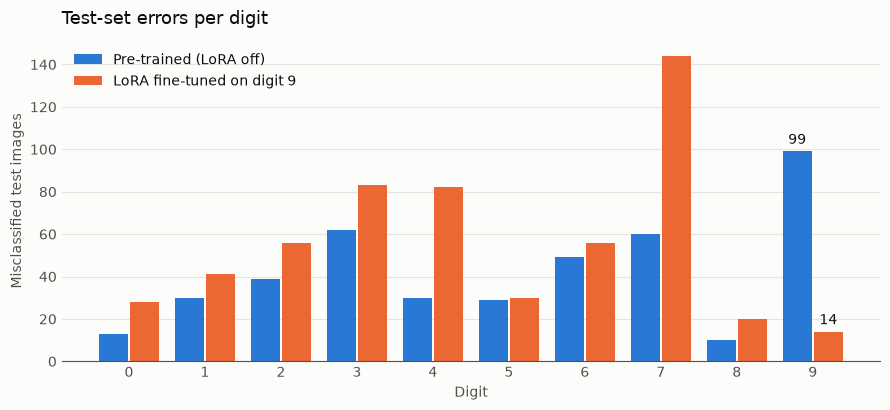

In [16]:
SURFACE, INK, INK_MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e6e5e1"
series = [
    ("Pre-trained (LoRA off)", base_wrong_counts, "#2a78d6"),
    (f"LoRA fine-tuned on digit {TARGET_DIGIT}", lora_wrong_counts, "#eb6834"),
]

fig, ax = plt.subplots(figsize=(9, 4.2), facecolor=SURFACE)
ax.set_facecolor(SURFACE)
width, gap = 0.38, 0.03
for i, (label, counts, color) in enumerate(series):
    offset = (i - 0.5) * (width + gap)
    bars = ax.bar([d + offset for d in range(10)], counts, width=width, color=color, label=label, zorder=2)
    # Label only the target digit, the bar the story is about
    target_bar = bars[TARGET_DIGIT]
    ax.annotate(f"{counts[TARGET_DIGIT]}", (target_bar.get_x() + target_bar.get_width() / 2, target_bar.get_height()),
                xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", color=INK, fontsize=10)

ax.set_xticks(range(10))
ax.set_xlabel("Digit", color=INK_MUTED)
ax.set_ylabel("Misclassified test images", color=INK_MUTED)
ax.set_title("Test-set errors per digit", color=INK, loc="left", fontsize=13, pad=12)
ax.tick_params(colors=INK_MUTED, length=0)
ax.grid(axis="y", color=GRID, linewidth=0.8, zorder=0)
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(INK_MUTED)
legend = ax.legend(frameon=False, loc="upper left", labelcolor=INK)
fig.tight_layout()

os.makedirs("assets", exist_ok=True)
fig.savefig("assets/errors_per_digit.png", dpi=150, facecolor=SURFACE)
plt.show()

## Merging LoRA into the base weights

At inference time LoRA adds **no latency**: since $W' = W + \frac{\alpha}{r}BA$ is just another matrix
of the same shape, we can compute it once and store it as a plain weight.

With LoRA enabled, `layer.weight` *is* the merged weight (the parametrization computes it), so we just
copy it into a fresh, plain `RichBoyNet`. That way `net` keeps its swappable adapter.

> **Gotcha:** if you don't need the adapter anymore, `parametrize.remove_parametrizations(layer, "weight",
> leave_parametrized=True)` merges in place. But don't call it on a `copy.deepcopy` of a parametrized
> model: the copy shares the dynamically created `ParametrizedLinear` class with the original, so removing
> the parametrization from the copy deletes the `weight` property from the original as well.

In [17]:
enable_disable_lora(net, enabled=True)
merged_net = RichBoyNet().to(device)
with torch.no_grad():
    for name in LORA_LAYERS:
        # W' = W + (B @ A) * scale, computed by the LoRA parametrization
        getattr(merged_net, name).weight.copy_(getattr(net, name).weight)
        getattr(merged_net, name).bias.copy_(getattr(net, name).bias)

# Plain nn.Linear layers with exactly the original number of parameters
assert not parametrize.is_parametrized(merged_net)
assert sum(p.numel() for p in merged_net.parameters()) == total_parameters_original
print(merged_net)

# Same outputs as the network with the LoRA adapter enabled
enable_disable_lora(net, enabled=True)
x, _ = next(iter(test_loader))
with torch.no_grad():
    max_diff = (net(x.to(device)) - merged_net(x.to(device))).abs().max().item()
print(f"\nMax |LoRA net - merged net| on a test batch: {max_diff:.2e}")
assert max_diff < 1e-4

merged_accuracy, merged_wrong_counts = evaluate(merged_net)
print(f"Accuracy (LoRA enabled): {lora_accuracy:.3f}")
print(f"Accuracy (merged):       {merged_accuracy:.3f}")

RichBoyNet(
  (linear1): Linear(in_features=784, out_features=1000, bias=True)
  (linear2): Linear(in_features=1000, out_features=2000, bias=True)
  (linear3): Linear(in_features=2000, out_features=10, bias=True)
  (relu): ReLU()
)

Max |LoRA net - merged net| on a test batch: 0.00e+00


Accuracy (LoRA enabled): 0.945
Accuracy (merged):       0.945


## Does the rank matter?

Repeat the same fine-tuning (100 batches of the target digit) starting from the same pre-trained
weights, for different ranks $r$. Following the paper, $\alpha$ is fixed to the first rank we tried
($\alpha = 1$), so the update is scaled by $1/r$.

In [18]:
print(f"{'rank':>4} | {'LoRA params':>11} | {'% of model':>10} | {'accuracy':>8} | {f'errors on {TARGET_DIGIT}':>11}")
print("-" * 58)
rank_results = []
for rank in [1, 2, 4, 8, 16]:
    torch.manual_seed(0)
    candidate = copy.deepcopy(pretrained_net)
    add_lora(candidate, rank=rank, lora_alpha=1)
    freeze_non_lora(candidate)
    train(candidate, target_loader, epochs=1, total_iterations_limit=100, progress=False)

    accuracy, wrong_counts = evaluate(candidate)
    lora_params = sum(m.lora_A.numel() + m.lora_B.numel() for m in lora_modules(candidate))
    rank_results.append((rank, lora_params, accuracy, wrong_counts[TARGET_DIGIT]))
    print(f"{rank:>4} | {lora_params:>11,} | {lora_params / total_parameters_original:>9.3%} | "
          f"{accuracy:>8.3f} | {wrong_counts[TARGET_DIGIT]:>11}")

rank | LoRA params | % of model | accuracy | errors on 9
----------------------------------------------------------


   1 |       6,794 |    0.242% |    0.891 |          17


   2 |      13,588 |    0.484% |    0.935 |          10


   4 |      27,176 |    0.968% |    0.946 |           8


   8 |      54,352 |    1.936% |    0.944 |           9


  16 |     108,704 |    3.873% |    0.951 |           8


## Takeaways

- **Tiny trainable footprint.** A rank-1 adapter adds about 0.24% parameters, yet it is enough to
  change the network's behaviour on the target digit dramatically.
- **The base model is never touched.** The asserts above prove the frozen weights are bit-for-bit
  identical after fine-tuning, and disabling the adapter gives back exactly the pre-trained results.
  That's what makes LoRA adapters cheap to store and swap: one base model, many small adapters.
- **No inference overhead.** The adapter can be merged into the base weights, giving a plain network
  with the original parameter count and the same outputs.
- **LoRA doesn't prevent forgetting on the task.** We fine-tuned on a single digit only, so the adapted
  network becomes biased towards predicting that digit: errors on several other digits go up and the
  overall accuracy drops. LoRA restricts *how* the weights can change, not *what* they are optimized for;
  in practice you'd fine-tune on data that is representative of the target task (e.g. mix in the other digits).
- **Rank: small is often enough.** In the sweep, every rank fixes most of the target-digit errors, and
  higher ranks mainly recover some overall accuracy. This is a single seed, though: the rank-1 run in the
  sweep differs from the main run above only in its random initialization and batch order, and its
  accuracy is noticeably different. Treat these numbers as indicative, not as a benchmark.